In [ ]:
!pip uninstall torch torchvision torchaudio peft -y -q
!pip install "vllm" "xformers" "trl" "peft" "bitsandbytes" --upgrade --no-cache-dir -q
!pip install "unsloth[vllm]" --upgrade --no-deps -q
!pip install unsloth_zoo -q
!pip install "pillow==10.4.0" "numpy<2.0" -q

In [1]:
from unsloth import FastLanguageModel, PatchFastRL, is_bfloat16_supported
from datasets import load_dataset, Dataset
from trl import GRPOConfig, GRPOTrainer
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd
import shutil
import torch
import re
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# os.environ["UNSLOTH_DISABLE_ZOO"] = "1"
# os.environ["VLLM_DISABLE_GUIDED_DECODING"] = "1"
# os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"
# os.environ["VLLM_GPU_IDS"] = "1"

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [2]:
PatchFastRL("GRPO", FastLanguageModel)

max_seq_length = 2048
lora_rank = 64

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/mistral-7b-instruct-v0.3",
    max_seq_length = max_seq_length,
    load_in_4bit = False,
    fast_inference = False,
)

model.load_adapter("mistral_sft_final", adapter_name="sft")

for name, param in model.named_parameters():
    if "lora" in name and "sft" in name:
        param.requires_grad = False

model = FastLanguageModel.get_peft_model(
    model,
    r = lora_rank,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj"],
    lora_alpha = lora_rank//2,
    use_gradient_checkpointing = "unsloth",
    random_state = 42,
    use_rslora = False,
)

Unsloth: UnslothBCOTrainer is already patched.
Unsloth: UnslothCPOTrainer is already patched.
Unsloth: UnslothDPOTrainer is already patched.
Unsloth: UnslothGKDTrainer is already patched.
Unsloth: UnslothGRPOTrainer is already patched.
Unsloth: UnslothKTOTrainer is already patched.
Unsloth: UnslothNashMDTrainer is already patched.
Unsloth: UnslothOnlineDPOTrainer is already patched.
Unsloth: UnslothORPOTrainer is already patched.
Unsloth: UnslothPPOTrainer is already patched.
Unsloth: UnslothPRMTrainer is already patched.
Unsloth: UnslothRewardTrainer is already patched.
Unsloth: UnslothRLOOTrainer is already patched.
Unsloth: UnslothSFTTrainer is already patched.
Unsloth: UnslothXPOTrainer is already patched.


==((====))==  Unsloth 2025.12.5: Fast Mistral patching. Transformers: 4.57.3. vLLM: 0.12.0.
   \\   /|    NVIDIA L4. Num GPUs = 1. Max memory: 22.278 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.9.0+cu128. CUDA: 8.9. CUDA Toolkit: 12.8. Triton: 3.5.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.33.post1. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/peft/mapping_func.py:72: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:282: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(
Unsloth 2025.12.5 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


# Dataset Loading

In [3]:
gsm = load_dataset("openai/gsm8k", "main")
train_raw = gsm["train"].shuffle(seed=42)

EVAL_SIZE = 500
SFT_SIZE  = 4000
RL_SIZE   = 2900

rl_raw = train_raw.select(range(EVAL_SIZE + SFT_SIZE, EVAL_SIZE + SFT_SIZE + RL_SIZE))

print(f"RL Dataset Size: {len(rl_raw)}")

RL Dataset Size: 2900


# GRPO Prompt

In [4]:
GRPO_SYSTEM_PROMPT = """Respond in the following format:
<reasoning>
...
</reasoning>
<answer>
...
</answer>"""

def format_for_grpo(example):
    return {
        "prompt": [
            {"role": "system", "content": GRPO_SYSTEM_PROMPT},
            {"role": "user", "content": example["question"]},
        ],
        "answer": example["answer"],
    }

rl_dataset = rl_raw.map(format_for_grpo)
print("Sample Prompt:", rl_dataset[0]["prompt"])

Sample Prompt: [{'content': 'Respond in the following format:\n<reasoning>\n...\n</reasoning>\n<answer>\n...\n</answer>', 'role': 'system'}, {'content': 'In January the families visiting a national park see animals 26 times. In February the families that visit the national park see animals three times as many as were seen there in January. Then in March the animals are shyer and the families who visit the national park see animals half as many times as they were seen in February. How many times total did families see an animal in the first three months of the year?', 'role': 'user'}]


# Reward Function

In [5]:
# Reward 1: XML Format Compliance
def format_reward_func(completions, **kwargs):
    rewards = []
    for c in completions:
        txt = c[0]["content"]
        r = 0.0
        if "<reasoning>" in txt and "</reasoning>" in txt:
            r += 0.3
        if "<answer>" in txt and "</answer>" in txt:
            r += 0.3
        rewards.append(r)
    return rewards

# Reward 2: Mathematical Correctness
def correctness_reward_func(prompts, completions, answer, **kwargs):
    rewards = []
    for c, gold in zip(completions, answer):
        try:
            ans = c[0]["content"].split("<answer>")[-1].split("</answer>")[0]
            pred = float(re.findall(r"-?\d+\.?\d*", ans)[-1])
            gold_val = float(re.findall(r"-?\d+\.?\d*", gold)[-1])
            diff = abs(pred - gold_val)

            if diff < 1e-5:
                rewards.append(1.5)
            elif diff < 1e-2:
                rewards.append(0.5)
            else:
                rewards.append(0.0)
        except:
            rewards.append(0.0)
    return rewards

# GRPO Training

In [6]:
model.train()

training_args = GRPOConfig(
    use_vllm = False,
    # vllm_mode="colocate",
    # vllm_gpu_memory_utilization = 0.4,
    learning_rate = 2e-6,
    adam_beta1 = 0.9,
    adam_beta2 = 0.95,
    weight_decay = 0.05,
    warmup_ratio = 0.05,
    lr_scheduler_type = "cosine",
    optim = "adamw_8bit",
    logging_steps = 5,
    bf16 = True,
    fp16 = False,
    
    per_device_train_batch_size = 2,
    gradient_accumulation_steps = 4,
    num_generations = 4,
    
    max_prompt_length = 512,
    max_completion_length = 512,

    max_steps = 800,
    save_strategy = "steps",
    save_steps = 100,
    save_total_limit = 1,
    max_grad_norm = 1.0,
    report_to = "none",
    output_dir = "mistral_grpo_rl",
)

trainer = GRPOTrainer(
    model = model,
    processing_class = tokenizer,
    reward_funcs = [
        format_reward_func,
        correctness_reward_func,
    ],
    train_dataset = rl_dataset,
    args = training_args,
)

print("Starting GRPO Training...")
trainer.train()

The model is already on multiple devices. Skipping the move to device specified in `args`.


Starting GRPO Training...


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 2,900 | Num Epochs = 1 | Total steps = 800
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 209,715,200 of 7,457,738,752 (2.81% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,sampling / sampling_logp_difference / mean,sampling / sampling_logp_difference / max,sampling / importance_sampling_ratio / min,sampling / importance_sampling_ratio / mean,sampling / importance_sampling_ratio / max,kl,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correctness_reward_func / mean,rewards / correctness_reward_func / std
5,0.000000,1.087500,0.411284,258.950000,175.200000,368.200000,0.000000,258.950000,175.200000,368.200000,0,0,0,0,0,0.000383,0.525000,0.111210,0.562500,0.737309
10,0.000000,1.260000,0.737012,209.850000,132.600000,328.400000,0.025000,201.500003,132.600000,276.400000,No Log,No Log,No Log,No Log,No Log,0.000419,0.547500,0.133841,0.712500,0.765024
15,0.000000,1.132500,0.485851,299.875000,183.000000,468.200000,0.050000,289.321436,183.000000,412.400000,No Log,No Log,No Log,No Log,No Log,0.000418,0.532500,0.091414,0.600000,0.539077
20,0.000000,1.155000,0.533221,278.525000,172.600000,407.600000,0.050000,269.241669,172.600000,403.800000,No Log,No Log,No Log,No Log,No Log,0.000727,0.517500,0.114842,0.637500,0.555469
25,0.000000,1.117500,0.715814,228.600000,124.800000,415.800000,0.025000,221.632144,124.800000,383.800000,No Log,No Log,No Log,No Log,No Log,0.001218,0.480000,0.192169,0.637500,0.732241
30,0.000000,0.990000,0.277614,293.525000,179.000000,452.800000,0.050000,285.182153,179.000000,432.800000,No Log,No Log,No Log,No Log,No Log,0.000621,0.540000,0.150707,0.450000,0.560561
35,0.000000,1.087500,0.491479,225.225000,135.000000,360.800000,0.000000,225.225000,135.000000,360.800000,No Log,No Log,No Log,No Log,No Log,0.000682,0.525000,0.131709,0.562500,0.715825
40,0.000000,1.125000,0.261962,297.150000,195.000000,497.600000,0.100000,274.303580,195.000000,430.400000,No Log,No Log,No Log,No Log,No Log,0.000922,0.525000,0.150242,0.600000,0.532846
45,0.000000,1.125000,0.514975,280.575000,180.600000,439.000000,0.025000,273.646429,180.600000,420.800000,No Log,No Log,No Log,No Log,No Log,0.000744,0.487500,0.231900,0.637500,0.775208
50,0.000100,1.080000,0.565737,266.325000,160.200000,470.000000,0.050000,253.828577,160.200000,410.200000,No Log,No Log,No Log,No Log,No Log,0.068186,0.517500,0.199695,0.562500,0.666627


TrainOutput(global_step=800, training_loss=0.0003572594177285282, metrics={'train_runtime': 38338.443, 'train_samples_per_second': 0.167, 'train_steps_per_second': 0.021, 'total_flos': 0.0, 'train_loss': 0.0003572594177285282})

# Saving Model

In [7]:
model.save_pretrained("mistral_grpo_final_lora")
tokenizer.save_pretrained("mistral_grpo_final_lora")

print("Saved GRPO LoRA adapters.")

Saved GRPO LoRA adapters.


In [8]:
shutil.make_archive("mistral_grpo_final_lora",  "zip", "./mistral_grpo_final_lora")
print("Archives created!")

Archives created!


# Scoring Functions

In [9]:
def extract_answer_number(text):
    if text is None: return None
    # Look for the answer in the XML tag first (since we trained for it)
    if "<answer>" in text and "</answer>" in text:
        text = text.split("<answer>")[-1].split("</answer>")[0]
    elif "####" in text:
        text = text.split("####")[-1]
    
    # Extract the last number found
    nums = re.findall(r"-?\d+\.?\d*", text.replace(",", ""))
    return float(nums[-1]) if nums else None

def generate_batch(model, tokenizer, questions, batch_size=8):
    # Enable vLLM fast inference if available
    FastLanguageModel.for_inference(model) 
    
    generated_texts = []
    
    # Prepare prompts with the correct template
    prompts = [
        f"""Respond in the following format:
<reasoning>
...
</reasoning>
<answer>
...
</answer>
User: {q}""" for q in questions
    ]
    
    # Process in batches
    for i in tqdm(range(0, len(prompts), batch_size), desc="Evaluating"):
        batch_prompts = prompts[i:i+batch_size]
        
        # Tokenize
        inputs = tokenizer(
            batch_prompts, 
            return_tensors="pt", 
            padding=True, 
            truncation=True
        ).to("cuda")
        
        # Generate
        with torch.no_grad():
            outputs = model.generate(
                **inputs, 
                max_new_tokens=512,
                use_cache=True,
                pad_token_id=tokenizer.pad_token_id
            )
        
        # Decode
        decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)
        # We only want the newly generated part, but standard decode gives full text.
        # Simple split by "User: ... \n" or just taking the end is safer for now.
        generated_texts.extend(decoded)
        
    return generated_texts

def score_model(predictions, gold_answers):
    correct = 0
    results = []
    
    for pred, gold in zip(predictions, gold_answers):
        # Extract predicted number
        pred_val = extract_answer_number(pred)
        
        # Extract gold number
        try:
            clean_gold = str(gold).split("####")[-1].replace(",", "").strip()
            gold_val = float(re.findall(r"-?\d+\.?\d*", clean_gold)[-1])
        except:
            gold_val = 0.0
            
        # Check correctness
        is_correct = pred_val is not None and abs(pred_val - gold_val) < 1e-5
        if is_correct: correct += 1
        
        results.append({
            "prediction": pred,
            "gold": gold,
            "pred_val": pred_val,
            "gold_val": gold_val,
            "is_correct": is_correct
        })
        
    accuracy = correct / len(predictions) * 100
    return accuracy, pd.DataFrame(results)

# Run Eval

In [10]:
eval_data = train_raw.select(range(EVAL_SIZE)) 
eval_questions = eval_data["question"]
eval_golds = eval_data["answer"]

print(f"Running Evaluation on {len(eval_questions)} examples...")

rl_preds = generate_batch(model, tokenizer, eval_questions, batch_size=4)

rl_acc, rl_results = score_model(rl_preds, eval_golds)

print(f"RL Model Accuracy: {rl_acc:.2f}%")

rl_results.to_csv("rl_evaluation_results.csv", index=False)
print("Saved detailed results to rl_evaluation_results.csv")

print("\nSample Output:")
print(rl_results.iloc[0]["prediction"])

Running Evaluation on 500 examples...


Evaluating: 100%|██████████| 125/125 [1:00:20<00:00, 28.96s/it]

RL Model Accuracy: 45.40%
Saved detailed results to rl_evaluation_results.csv

Sample Output:
Respond in the following format:
<reasoning>
...
</reasoning>
<answer>
...
</answer>
User: Mimi picked up 2 dozen seashells on the beach.  Kyle found twice as many shells as Mimi and put them in his pocket. Leigh grabbed one-third of the shells that Kyle found.  How many seashells did Leigh have?

<reasoning>
1. Mimi picked up 2 dozen seashells, which is 24 seashells (since 1 dozen = 12).
2. Kyle found twice as many seashells as Mimi, so he found 2 * 24 = 48 seashells.
3. Leigh grabbed one-third of the seashells that Kyle found, so she grabbed 1/3 * 48 = 16 seashells.
</reasoning>

<answer>
Leigh had 16 seashells.
</answer>


In [11]:
logs = trainer.state.log_history

df = pd.DataFrame(logs)

df = df[df.get("step").notna()]

df.to_csv("grpo_training_log.csv", index=False)
print("Saved training log to grpo_training_log.csv")
print(df.columns)
df.tail()

Saved training log to grpo_training_log.csv
Index(['loss', 'grad_norm', 'learning_rate', 'num_tokens',
       'completions/mean_length', 'completions/min_length',
       'completions/max_length', 'completions/clipped_ratio',
       'completions/mean_terminated_length',
       'completions/min_terminated_length',
       'completions/max_terminated_length', 'rewards/format_reward_func/mean',
       'rewards/format_reward_func/std',
       'rewards/correctness_reward_func/mean',
       'rewards/correctness_reward_func/std', 'reward', 'reward_std',
       'frac_reward_zero_std', 'completion_length', 'kl', 'epoch', 'step',
       'train_runtime', 'train_samples_per_second', 'train_steps_per_second',
       'total_flos', 'train_loss'],
      dtype='object')


,loss,grad_norm,learning_rate,num_tokens,completions/mean_length,completions/min_length,completions/max_length,completions/clipped_ratio,completions/mean_terminated_length,completions/min_terminated_length,...,frac_reward_zero_std,completion_length,kl,epoch,step,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
156,0.0000,1.182848,2.186373e-09,2099692.0,205.350,130.2,305.8,0.000,205.350000,130.2,...,0.4,205.350,0.041505,0.541379,785,NaN,NaN,NaN,NaN,NaN
157,0.0000,0.001806,1.033601e-09,2112362.0,207.550,148.8,295.0,0.000,207.550000,148.8,...,0.3,207.550,0.040031,0.544828,790,NaN,NaN,NaN,NaN,NaN
158,0.0000,1.430209,3.075550e-10,2125043.0,223.525,122.0,420.8,0.025,216.567859,122.0,...,0.3,223.525,0.044993,0.548276,795,NaN,NaN,NaN,NaN,NaN
159,0.0001,1.164439,8.543620e-12,2140398.0,270.375,160.4,436.8,0.050,257.882150,160.4,...,0.4,270.375,0.060431,0.551724,800,NaN,NaN,NaN,NaN,NaN
160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.551724,800,38338.443,0.167,0.021,0.0,0.000357


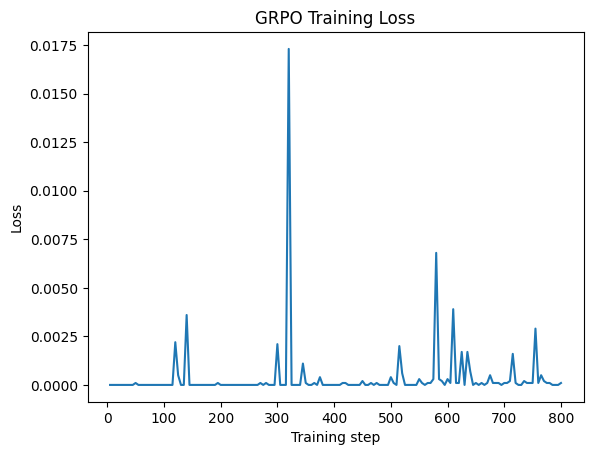

In [12]:
plt.figure()
plt.plot(df["step"], df["loss"])
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("GRPO Training Loss")
plt.show()

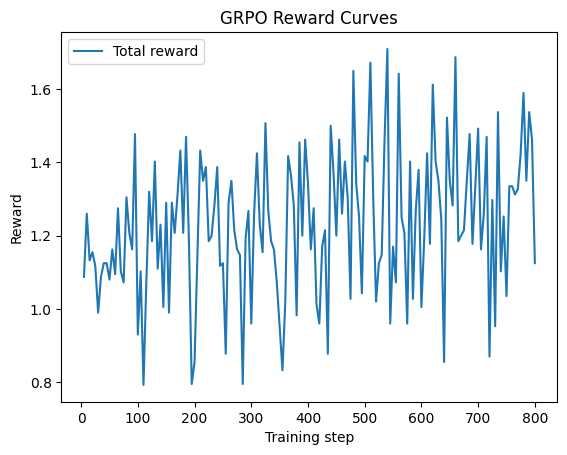

In [13]:
plt.figure()

if "reward/format_reward_func" in df:
    plt.plot(df["step"], df["reward/format_reward_func"], label="Format reward")

if "reward/correctness_reward_func" in df:
    plt.plot(df["step"], df["reward/correctness_reward_func"], label="Correctness reward")

if "reward" in df:
    plt.plot(df["step"], df["reward"], label="Total reward")

plt.xlabel("Training step")
plt.ylabel("Reward")
plt.title("GRPO Reward Curves")
plt.legend()
plt.show()

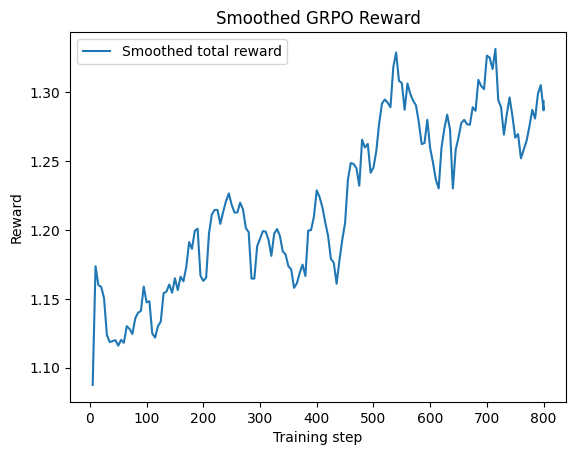

In [14]:
def smooth(series, window=20):
    return series.rolling(window, min_periods=1).mean()

plt.figure()
plt.plot(df["step"], smooth(df["reward"]), label="Smoothed total reward")
plt.xlabel("Training step")
plt.ylabel("Reward")
plt.title("Smoothed GRPO Reward")
plt.legend()
plt.show()